# 14 · Camera calibration and pose

**Level:** Advanced / guided expert practice  
**Prerequisites:** Image coordinates; Perspective transformations; NumPy arrays

## What you will build and learn

- Estimate intrinsics from several known planar targets
- Separate reprojection error from parameter accuracy
- Estimate pose and validate on a held-out view

## How to use this lesson

Run cells in order with **Shift+Enter**. Predict the result before running each example, then change one parameter and explain what changed. Every default example works offline after setup. Each notebook creates its own data, so previous notebooks do not need to have been run.

Try the exercises before reading the worked solutions. Use **Kernel → Restart Kernel and Run All Cells** to check that your work is reproducible. Keep your own changes in a duplicate notebook if you want to retain the reference version.


## Setup

The cell below imports the libraries and the small display/file helpers. Algorithms are written in the lesson cells. Color arrays passed to `show_images` are assumed to be BGR (OpenCV's usual order); the helper converts them to RGB for Matplotlib. Grayscale arrays are displayed directly. `rng` is a repeatable random generator, so running the notebook again reproduces its sample data.


In [1]:
from pathlib import Path
import sys

# Locate the project whether Jupyter starts in the project or notebooks folder.
start = Path.cwd().resolve()
ROOT = next((p for p in (start, *start.parents) if (p / "course_utils.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the OpenCV Practical project.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import matplotlib.pyplot as plt
from course_utils import show_images, make_scene, load_image, save_image

rng = np.random.default_rng(42)
cv2.setRNGSeed(42)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
print(f"OpenCV {cv2.__version__} | NumPy {np.__version__}")


OpenCV 4.14.0 | NumPy 2.5.3


## Step 1 — Define a camera and a measured target
A pinhole camera projects 3D camera coordinates with `u = fx*X/Z + cx`, `v = fy*Y/Z + cy`. The intrinsic matrix K contains focal lengths **in pixels** and the principal point. Distortion bends these ideal projections. Extrinsics rotate and translate world points into the camera frame.

Our board contains **9 × 6 inner corners**, spaced **0.025 metres** apart. Those units determine the units of estimated translation. We know the synthetic camera, so we can check estimated parameters as well as image error.


In [2]:
calibration_rng = np.random.default_rng(140)
image_size = (640, 480)  # OpenCV uses (width, height)
board_size = (9, 6)     # INNER corner columns, rows
square_m = 0.025
object_points = np.zeros((board_size[0]*board_size[1], 3), np.float32)
object_points[:, :2] = np.mgrid[0:board_size[0], 0:board_size[1]].T.reshape(-1, 2)
object_points[:, :2] *= square_m
object_points[:, :2] -= object_points[:, :2].mean(axis=0)
K_true = np.array([[800., 0., 320.], [0., 815., 240.], [0., 0., 1.]])
dist_true = np.array([-0.12, 0.04, 0., 0., 0.])  # k1, k2, p1, p2, k3
print('Known K:\n', K_true)
print('Board extent (m):', np.ptp(object_points[:, :2], axis=0))


Known K:
 [[800.   0. 320.]
 [  0. 815. 240.]
 [  0.   0.   1.]]
Board extent (m): [0.2   0.125]


Calibration needs varied views: tilt the target and move it across the image. A pile of nearly identical frontal views adds little geometric information. Here we generate corner observations directly; this isolates calibration from corner-detection mistakes.


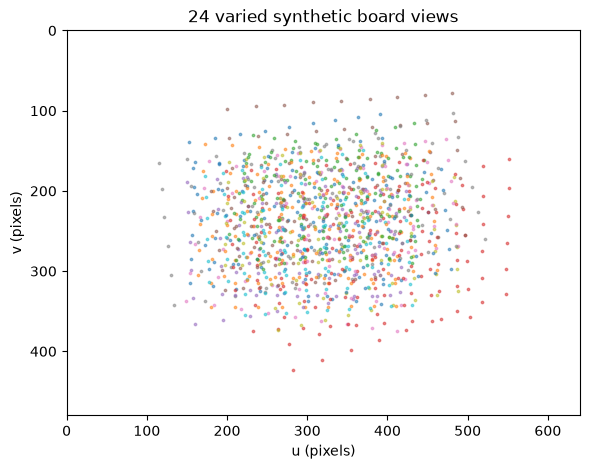

In [3]:
observations, rotations_true, translations_true = [], [], []
for i in range(24):
    rotation = calibration_rng.uniform([-0.45, -0.5, -0.2], [0.45, 0.5, 0.2])
    translation = calibration_rng.uniform([-0.065, -0.045, 0.48], [0.065, 0.045, 0.78])
    projected, _ = cv2.projectPoints(object_points, rotation, translation, K_true, dist_true)
    observed = projected + calibration_rng.normal(0, 0.12, projected.shape)
    observations.append(observed.astype(np.float32))
    rotations_true.append(rotation)
    translations_true.append(translation)
fig, ax = plt.subplots(figsize=(7, 5))
for i, corners in enumerate(observations):
    ax.scatter(corners[:, 0, 0], corners[:, 0, 1], s=3, alpha=0.5)
ax.set(xlim=(0, image_size[0]), ylim=(image_size[1], 0), xlabel='u (pixels)', ylabel='v (pixels)',
       title='24 varied synthetic board views'); ax.set_aspect('equal'); plt.show()


## Step 2 — Detect and refine real image corners
The next tiny rendered board demonstrates the detector API. A 9×6 inner-corner board has 10×7 squares. This frontal image alone is **not** the calibration dataset. Real capture should contain sharp, fully visible, tilted boards distributed across the frame.


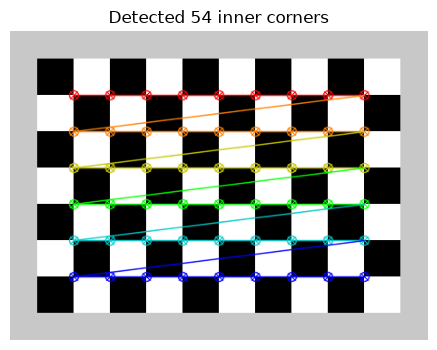

In [4]:
cell_px = 40
board = np.full((7*cell_px + 60, 10*cell_px + 60), 200, np.uint8)
for row in range(7):
    for col in range(10):
        color = 255 if (row+col) % 2 else 0
        cv2.rectangle(board, (30+col*cell_px, 30+row*cell_px),
                       (30+(col+1)*cell_px-1, 30+(row+1)*cell_px-1), color, -1)
detected, corners = cv2.findChessboardCorners(board, board_size)
assert detected, 'The generated board should be detectable.'
refined = cv2.cornerSubPix(board, corners, (5, 5), (-1, -1),
                         (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 30, 0.001))
board_view = cv2.cvtColor(board, cv2.COLOR_GRAY2BGR)
cv2.drawChessboardCorners(board_view, board_size, refined, detected)
show_images([board_view], [f'Detected {len(refined)} inner corners'])


Subpixel refinement estimates the corner location between pixel centres. It does not rescue a wrong corner ordering, an incorrect board size, or a target that is bent rather than planar.


## Step 3 — Calibrate and assess identifiable parameters
`calibrateCamera` jointly fits K, distortion, and one pose per image. We fix k3 and tangential distortion to their known zero values to keep this controlled model appropriately small. On real data, justify flags from the camera model and validation, not from a desire for a lower training error.


In [5]:
calibration_flags = cv2.CALIB_FIX_K3 | cv2.CALIB_ZERO_TANGENT_DIST
def calibrate(corner_sets):
    return cv2.calibrateCamera([object_points.copy() for _ in corner_sets], corner_sets,
                               image_size, None, None, flags=calibration_flags)
rms, K_est, dist_est, rvecs, tvecs = calibrate(observations)
print('Calibration RMS (pixels):', rms)
print('Estimated K:\n', K_est.round(3))
print('Estimated distortion:', dist_est.ravel().round(5))
focal_relative_error = np.abs(np.diag(K_est)[:2] / np.diag(K_true)[:2] - 1)
print('Focal relative error:', focal_relative_error)
print('Principal point error (pixels):', np.linalg.norm(K_est[:2, 2] - K_true[:2, 2]))
assert rms < 0.5 and np.max(focal_relative_error) < 0.05


Calibration RMS (pixels): 0.16483371600493907
Estimated K:
 [[799.686   0.    320.156]
 [  0.    814.843 240.268]
 [  0.      0.      1.   ]]
Estimated distortion: [-0.1234   0.12366  0.       0.       0.     ]
Focal relative error: [0.00039239 0.00019217]
Principal point error (pixels): 0.30960452949655626


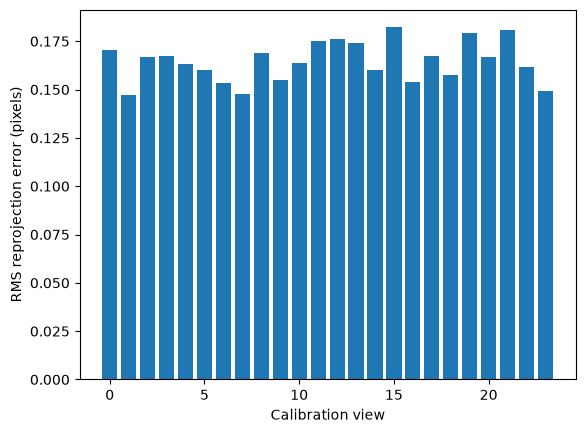

In [6]:
view_errors = []
for detected_points, rvec, tvec in zip(observations, rvecs, tvecs):
    reprojected, _ = cv2.projectPoints(object_points, rvec, tvec, K_est, dist_est)
    residual = detected_points[:, 0] - reprojected[:, 0]
    view_errors.append(np.sqrt(np.mean(np.sum(residual**2, axis=1))))
plt.bar(np.arange(len(view_errors)), view_errors)
plt.xlabel('Calibration view'); plt.ylabel('RMS reprojection error (pixels)'); plt.show()
assert np.isclose(np.sqrt(np.mean(np.array(view_errors)**2)), rms, atol=1e-3)


A low reprojection error can coexist with poor focal or distortion estimates if views are uninformative. Since synthetic ground truth is available, inspect both. High-order distortion is particularly difficult to identify without points near the image boundaries.


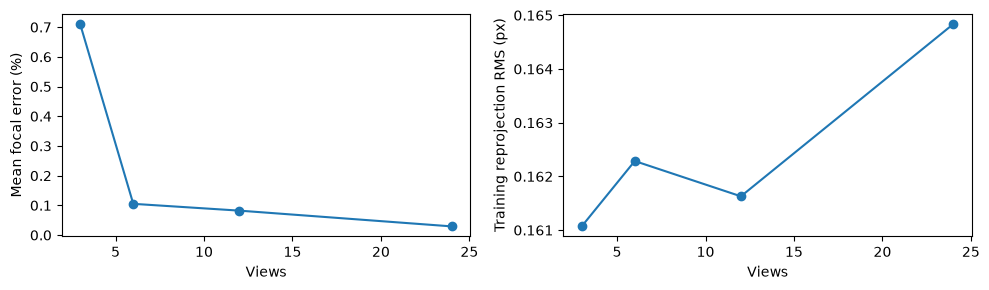

In [7]:
sample_counts, focal_errors, fitted_rms = [3, 6, 12, 24], [], []
for count in sample_counts:
    subset_rms, subset_K, _, _, _ = calibrate(observations[:count])
    fitted_rms.append(subset_rms)
    focal_errors.append(100*np.mean(np.abs(np.diag(subset_K)[:2]/np.diag(K_true)[:2]-1)))
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(sample_counts, focal_errors, 'o-'); axes[0].set(xlabel='Views', ylabel='Mean focal error (%)')
axes[1].plot(sample_counts, fitted_rms, 'o-'); axes[1].set(xlabel='Views', ylabel='Training reprojection RMS (px)')
plt.tight_layout(); plt.show()


## Step 4 — Estimate pose on an unseen view
`solvePnP` uses known 3D-to-2D correspondences and a calibrated camera. Its returned translation is the target origin expressed in **camera coordinates**, not the camera's position in the world. OpenCV's usual camera axes are x right, y down, z forward.


In [8]:
test_rvec = np.array([0.27, -0.22, 0.12])
test_tvec = np.array([0.015, -0.02, 0.63])
test_image_points, _ = cv2.projectPoints(object_points, test_rvec, test_tvec, K_true, dist_true)
test_observed = (test_image_points + calibration_rng.normal(0, 0.12, test_image_points.shape)).astype(np.float32)
pose_ok, pose_rvec, pose_tvec = cv2.solvePnP(object_points, test_observed, K_est, dist_est,
                                          flags=cv2.SOLVEPNP_ITERATIVE)
assert pose_ok
R_est, _ = cv2.Rodrigues(pose_rvec)
R_true, _ = cv2.Rodrigues(test_rvec)
angle_error = np.degrees(np.arccos(np.clip((np.trace(R_est @ R_true.T)-1)/2, -1, 1)))
translation_error = np.linalg.norm(pose_tvec.ravel() - test_tvec)
heldout_reprojection, _ = cv2.projectPoints(object_points, pose_rvec, pose_tvec, K_est, dist_est)
heldout_rms = np.sqrt(np.mean(np.sum((heldout_reprojection-test_observed)**2, axis=2)))
print(f'Held-out RMS: {heldout_rms:.3f} px; rotation error: {angle_error:.3f} degrees')
print(f'Translation error: {translation_error*1000:.2f} mm')
print('Camera centre in board coordinates (m):', (-R_est.T @ pose_tvec).ravel())
assert heldout_rms < 1 and translation_error < 0.03


Held-out RMS: 0.164 px; rotation error: 0.156 degrees
Translation error: 0.39 mm
Camera centre in board coordinates (m): [-0.15874179 -0.13797988 -0.59405345]


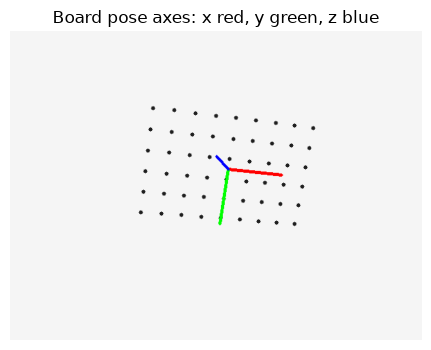

In [9]:
pose_canvas = np.full((image_size[1], image_size[0], 3), 245, np.uint8)
for p in test_observed[:, 0]:
    cv2.circle(pose_canvas, tuple(np.round(p).astype(int)), 3, (30, 30, 30), -1)
cv2.drawFrameAxes(pose_canvas, K_est, dist_est, pose_rvec, pose_tvec, 0.07, 3)
show_images([pose_canvas], ['Board pose axes: x red, y green, z blue'])


## Step 5 — Correct points and save reusable calibration
`undistortPoints(..., P=K)` returns corrected pixel coordinates. Without `P`, it returns normalized coordinates. Mixing those coordinate systems is a common source of plausible-looking geometry errors. Camera calibration belongs to a particular resolution and optical configuration.


Mean correction magnitude (pixels): 0.2289843


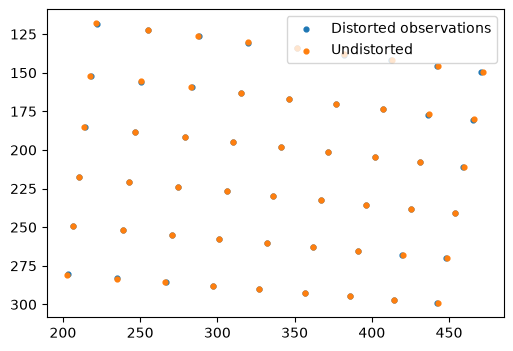

Saved: C:\Users\Hareram ray\AI\OpencvPractical\outputs\14_calibration\synthetic_calibration.npz


In [10]:
corrected_points = cv2.undistortPoints(test_observed, K_est, dist_est, P=K_est)
ideal_points, _ = cv2.projectPoints(object_points, test_rvec, test_tvec, K_true, np.zeros(5))
print('Mean correction magnitude (pixels):',
      np.mean(np.linalg.norm(corrected_points-test_observed, axis=2)))
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(test_observed[:, 0, 0], test_observed[:, 0, 1], label='Distorted observations', s=12)
ax.scatter(corrected_points[:, 0, 0], corrected_points[:, 0, 1], label='Undistorted', s=12)
ax.invert_yaxis(); ax.set_aspect('equal'); ax.legend(); plt.show()
calibration_dir = ROOT / 'outputs' / '14_calibration'
calibration_dir.mkdir(parents=True, exist_ok=True)
np.savez(calibration_dir / 'synthetic_calibration.npz', K=K_est, distortion=dist_est,
         image_size=image_size, square_size_m=square_m)
print('Saved:', calibration_dir / 'synthetic_calibration.npz')


## Step 6 — Expose a scale ambiguity
If every target dimension is doubled while the same image points are used, estimated translation doubles. Image reprojection alone cannot reveal that the ruler was wrong. This is why recording physical square size is essential.


In [11]:
ok_scaled, r_scaled, t_scaled = cv2.solvePnP(object_points*2, test_observed, K_est, dist_est)
assert ok_scaled
print('Original translation:', pose_tvec.ravel())
print('Wrong square-size translation:', t_scaled.ravel())
print('Ratio:', (t_scaled / pose_tvec).ravel())
np.testing.assert_allclose(t_scaled, 2*pose_tvec, rtol=1e-3, atol=1e-5)


Original translation: [ 0.01486089 -0.02018984  0.62968915]
Wrong square-size translation: [ 0.02972177 -0.04037967  1.25937831]
Ratio: [2. 2. 2.]


### Practice
1. Add one pixel of measurement noise to every corner and recalibrate. Compare parameter error and reprojection RMS.
2. Resize an image by 0.5. Derive the new K: focal lengths and principal point both scale, but distortion coefficients do not.
3. Explain why the 24 generated views validate geometry but do not test real corner detection, lens asymmetry, board warping, or rolling shutter.


In [12]:
# Your experiment area: increase this noise standard deviation.
extra_noise_px = 1.0
noisy_observations = [(p + calibration_rng.normal(0, extra_noise_px, p.shape)).astype(np.float32)
                      for p in observations]
print('Created', len(noisy_observations), 'noisier views; calibrate them next.')


Created 24 noisier views; calibrate them next.


### Worked solutions
Error need not improve monotonically with more views: view geometry, coverage, and measurement quality matter. Evaluate a fixed held-out view and inspect residual patterns when comparing capture strategies.


In [13]:
noisy_rms, noisy_K, _, _, _ = calibrate(noisy_observations)
print('Noisy RMS:', noisy_rms)
print('Noisy focal error (%):', 100*np.abs(np.diag(noisy_K)[:2]/np.diag(K_true)[:2]-1))
scale = 0.5
resized_K = K_est.copy()
resized_K[:2, :] *= scale
projected_full, _ = cv2.projectPoints(object_points, pose_rvec, pose_tvec, K_est, dist_est)
projected_half, _ = cv2.projectPoints(object_points, pose_rvec, pose_tvec, resized_K, dist_est)
np.testing.assert_allclose(projected_half, projected_full*scale, atol=1e-4)
print('Half-resolution K:\n', resized_K)
print('Resized-coordinate projection check passed.')


Noisy RMS: 1.3688917045303748
Noisy focal error (%): [0.34267298 0.22118703]
Half-resolution K:
 [[399.84304276   0.         160.07784685]
 [  0.         407.42169041 120.13380437]
 [  0.           0.           1.        ]]
Resized-coordinate projection check passed.


### References and next challenge
- [OpenCV camera calibration tutorial](https://docs.opencv.org/4.x/dc/dbb/tutorial_py_calibration.html)
- [OpenCV perspective-n-point pose documentation](https://docs.opencv.org/4.x/d5/d1f/calib3d_solvePnP.html)
- [Calibration and 3D reconstruction API](https://docs.opencv.org/4.x/d9/d0c/group__calib3d.html)

For a real calibration, capture a measured, rigid board at varied poses; reject blurred detections; check unseen images; record resolution, square units, camera, focus, and calibration date. Next we combine two cameras to estimate depth.
